# AI Crop-Safe Path Planning — Group 08\n\nThis notebook configures the field, runs BFS and DFS path simulations, and demonstrates BFS and DFS robots that detect unknown blockades and reroute that detects unknown blockades on attempted entry and replans to the goal.\n

## 1. Imports and field inputs
The setup cells collect all field dimensions and coordinate-based features from you. Coordinates are `(row, column)`, starting at `(0, 0)` in the top-left. Enter coordinate lists as `row,col; row,col`; leave blank for none.


In [1]:
from dataclasses import dataclass
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


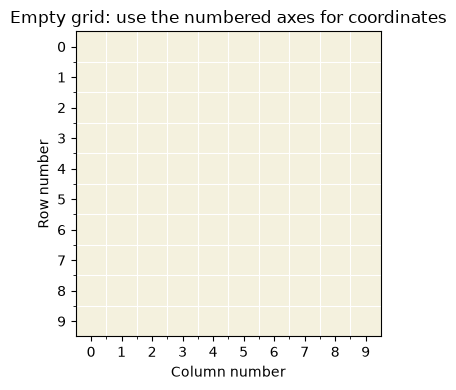

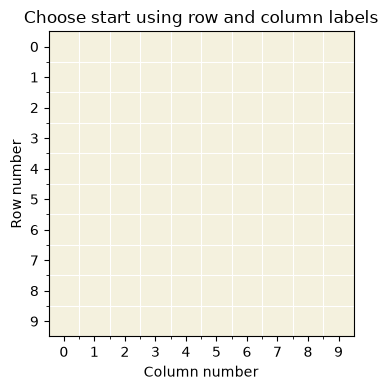

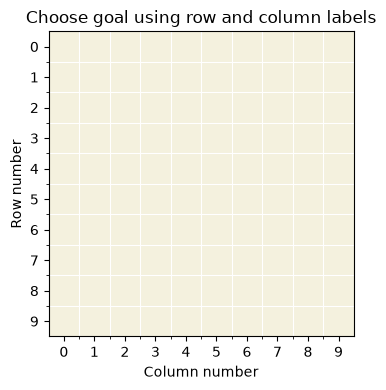

In [2]:
SAFE, POTATO, PROTECTED, BLOCKADE, START_CELL, GOAL_CELL, UNKNOWN = range(7)
SYMBOLS = {SAFE: ".", POTATO: "P", PROTECTED: "R", BLOCKADE: "X", START_CELL: "S", GOAL_CELL: "G", UNKNOWN: "?"}
COLORS = ["#f4f1de", "#4f772d", "#90a955", "#343a40", "#277da1", "#f94144", "#f8961e"]

def show_input_grid(grid, title="Current grid"):
    fig, ax = plt.subplots(figsize=(max(8, len(grid[0]) * 0.55), max(4, len(grid) * 0.38)))
    ax.imshow(grid, cmap=ListedColormap(COLORS), vmin=0, vmax=len(COLORS)-1)
    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticklabels(range(len(grid[0])))
    ax.set_yticklabels(range(len(grid)))
    ax.set_xticks([x-.5 for x in range(1, len(grid[0]))], minor=True)
    ax.set_yticks([y-.5 for y in range(1, len(grid))], minor=True)
    ax.grid(which="minor", color="white", linewidth=.8)
    ax.set_xlabel("Column number")
    ax.set_ylabel("Row number")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

def ask_int(prompt, minimum=0):
    while True:
        try:
            value = int(input(prompt))
            if value >= minimum:
                return value
            print(f"Enter a value of at least {minimum}.")
        except ValueError:
            print("Enter a whole number.")

def ask_coordinates(prompt, grid, title):
    show_input_grid(grid, title)
    raw = input(prompt).strip()
    if not raw:
        return []
    try:
        return [tuple(map(int, item.strip().split(','))) for item in raw.split(';')]
    except ValueError as error:
        raise ValueError("Use row,col pairs separated by semicolons, e.g. 1,2; 3,4") from error

ROWS = ask_int("Number of grid rows: ", 2)
COLS = ask_int("Number of grid columns: ", 2)
input_grid = [[SAFE for _ in range(COLS)] for _ in range(ROWS)]
show_input_grid(input_grid, "Empty grid: use the numbered axes for coordinates")
START = tuple(ask_coordinates("Start cell (row,col): ", input_grid, "Choose start using row and column labels")[0])
GOAL = tuple(ask_coordinates("Goal cell (row,col): ", input_grid, "Choose goal using row and column labels")[0])
if len(START) != 2 or len(GOAL) != 2:
    raise ValueError("Start and goal must each have two coordinates.")


## 2. Enter known field features
Each feature is entered in its own cell. Run the cell, inspect the updated grid plot, then continue to the next input. A blockade overrides crop and protection markings. Protection is limited to cells within the configured crop buffer.

In [3]:
def check_cells(cells, rows, cols, label):
    for cell in cells:
        if len(cell) != 2 or not (0 <= cell[0] < rows and 0 <= cell[1] < cols):
            raise ValueError(f"{label} cell {cell} is outside the {rows}x{cols} grid")

def build_current_field():
    grid = [[SAFE for _ in range(COLS)] for _ in range(ROWS)]
    crop_locations = set(crop_cells)
    for r, c in crop_locations:
        grid[r][c] = POTATO
    protection_zone = set()
    for cr, cc in crop_locations:
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            r, c = cr + dr, cc + dc
            if 0 <= r < ROWS and 0 <= c < COLS and (r, c) not in crop_locations:
                protection_zone.add((r, c))
    for cell in crop_protection_cells:
        if cell not in protection_zone:
            raise ValueError(f"Protection cell {cell} must be one Manhattan step from a crop cell.")
    for r, c in protection_zone:
        grid[r][c] = PROTECTED
    for r, c in crop_protection_cells:
        grid[r][c] = PROTECTED
    # Blockades have the highest priority and overwrite crops or protection.
    for r, c in known_blockades:
        grid[r][c] = BLOCKADE
    for cell, marker in ((START, START_CELL), (GOAL, GOAL_CELL)):
        r, c = cell
        if not (0 <= r < ROWS and 0 <= c < COLS):
            raise ValueError(f"Start/goal {cell} is outside the grid.")
        if grid[r][c] != SAFE:
            raise ValueError(f"Start/goal {cell} must be on an unoccupied safe cell.")
        grid[r][c] = marker
    return grid

known_blockades = []
crop_cells = []
crop_protection_cells = []
field = build_current_field()


### 2A. Known blockades
Enter known blockade coordinates here. The plot shows the current numbered grid; after you run this cell, the grid refreshes with blockades marked. Blockades have highest priority and can occupy crop or protection cells.

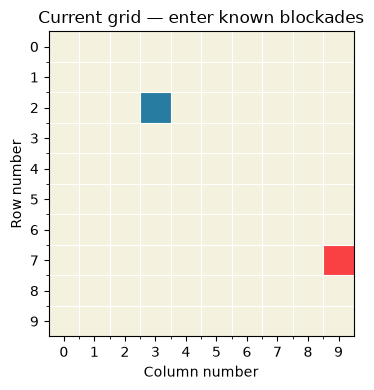

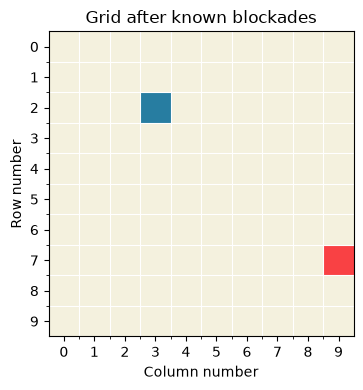

In [4]:
known_blockades = ask_coordinates("Known blockade cells (row,col; ...), blank for none: ", field, "Current grid — enter known blockades")
check_cells(known_blockades, ROWS, COLS, "Blockade")
field = build_current_field()
show_input_grid(field, "Grid after known blockades")


### 2C. Crop cells
Enter crop locations as individual `(row,column)` cells. The grid automatically marks the four orthogonal neighboring cells as protection, exactly one Manhattan step from each crop cell.

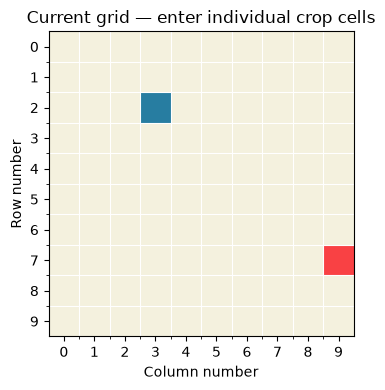

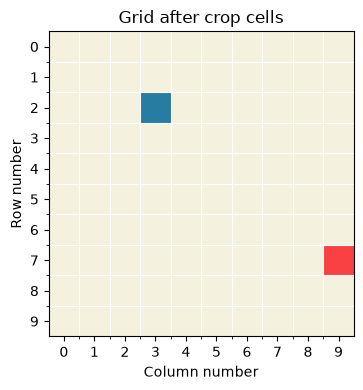

. . . . . . . . . .
. . . . . . . . . .
. . . S . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . G
. . . . . . . . . .
. . . . . . . . . .


In [5]:
crop_cells = ask_coordinates("Potato crop cells (row,col; ...), blank for none: ", field, "Current grid — enter individual crop cells")
check_cells(crop_cells, ROWS, COLS, "Crop")
field = build_current_field()
show_input_grid(field, "Grid after crop cells")
print("\n".join(" ".join(SYMBOLS[value] for value in row) for row in field))


### 2D. Additional protection cells (optional)\nProtection is automatically created one cell away from crops. You may optionally mark a subset of those adjacent cells explicitly; cells farther away from crops are rejected.\n

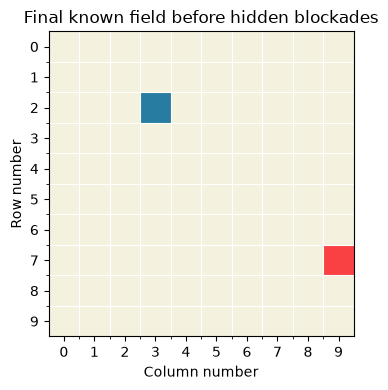

. . . . . . . . . .
. . . . . . . . . .
. . . S . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . G
. . . . . . . . . .
. . . . . . . . . .


In [6]:
# crop_protection_cells = ask_coordinates("Additional protected cells (row,col; ...), blank for none: ", field, "Current grid — enter additional protected cells")
# check_cells(crop_protection_cells, ROWS, COLS, "Protection")
field = build_current_field()
show_input_grid(field, "Final known field before hidden blockades")
print("\n".join(" ".join(SYMBOLS[value] for value in row) for row in field))


## 3. Enter initially unknown blockades\nThese are hidden from the robot at first. The cell below shows the current known grid before input and the true field after the hidden blockades are added.\n

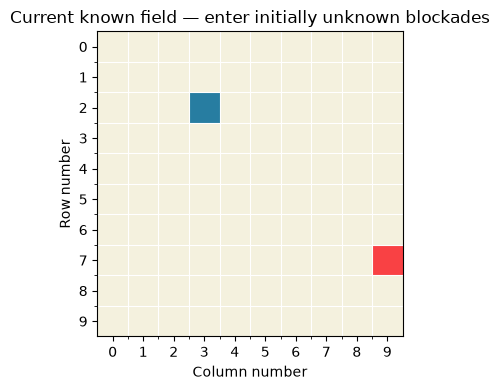

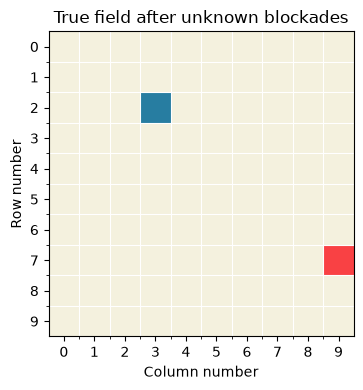

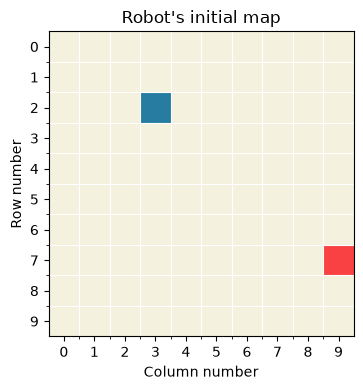

In [7]:
unknown_blockades = ask_coordinates("Unknown blockade cells (row,col; ...), blank for none: ", field, "Current known field — enter initially unknown blockades")
check_cells(unknown_blockades, ROWS, COLS, "Unknown blockade")

def add_unknown_blockades(known_field, unknown_cells):
    true_field = [row.copy() for row in known_field]
    robot_map = [row.copy() for row in known_field]
    for r, c in unknown_cells:
        if (r, c) in (START, GOAL):
            raise ValueError(f"Unknown blockade {(r, c)} cannot overlap start or goal.")
        true_field[r][c] = UNKNOWN
    return true_field, robot_map

true_field, known_field = add_unknown_blockades(field, unknown_blockades)
show_input_grid(true_field, "True field after unknown blockades")
show_input_grid(known_field, "Robot's initial map")


## 4. View the field and robot map
`true_field` shows all blockades; `known_field` hides initially unknown ones from the robot.

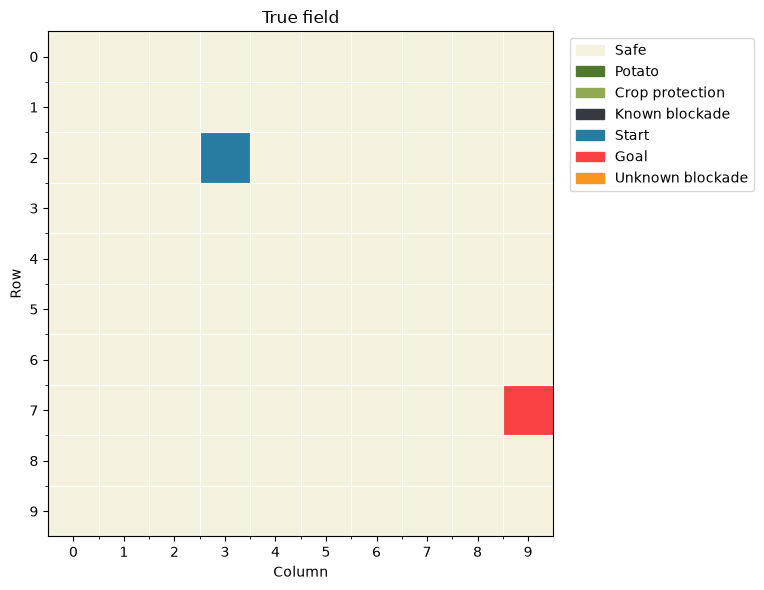

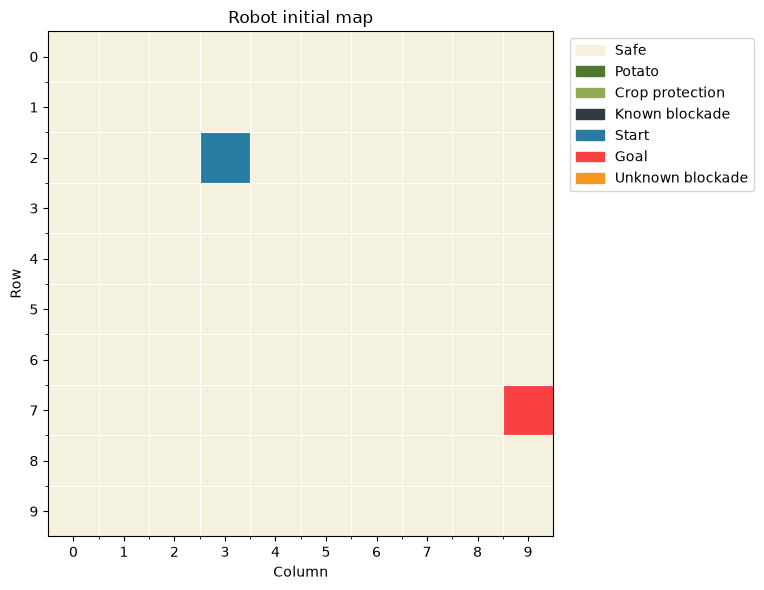

In [8]:
def show_field(grid, title):
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.imshow(grid, cmap=ListedColormap(COLORS), vmin=0, vmax=len(COLORS)-1)
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticks([x-.5 for x in range(1, COLS)], minor=True)
    ax.set_yticks([y-.5 for y in range(1, ROWS)], minor=True)
    ax.grid(which="minor", color="white", linewidth=.8)
    ax.set_xlabel("Column"); ax.set_ylabel("Row"); ax.set_title(title)
    labels = ["Safe", "Potato", "Crop protection", "Known blockade", "Start", "Goal", "Unknown blockade"]
    ax.legend(handles=[plt.Rectangle((0,0),1,1,color=color,label=label) for color,label in zip(COLORS,labels)], bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout(); plt.show()

show_field(true_field, "True field")
show_field(known_field, "Robot initial map")


## 5. Problem formulation
- **State:** current `(row, column)` position.
- **Initial state:** `START`.
- **Actions:** one-cell Up, Down, Left, or Right; no diagonal movement.
- **Transition:** apply the selected unit offset if the destination cell is in bounds and traversable in the robot’s current map.
- **Goal test:** current position equals `GOAL`.
- **Basic path cost:** 1 per move. Crop proximity penalties are a later crop-safe planning step.

In [9]:
MOVES = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1)}
IMPASSABLE = {POTATO, PROTECTED, BLOCKADE, UNKNOWN}

@dataclass
class PathPlanningProblem:
    grid: list
    start: tuple
    goal: tuple

    def actions(self, state):
        result = []
        for action, (dr, dc) in MOVES.items():
            nr, nc = state[0] + dr, state[1] + dc
            if 0 <= nr < len(self.grid) and 0 <= nc < len(self.grid[0]) and self.grid[nr][nc] not in IMPASSABLE:
                result.append(action)
        return result

    def transition(self, state, action):
        if action not in self.actions(state):
            raise ValueError(f"Illegal action {action} from {state}")
        dr, dc = MOVES[action]
        return state[0] + dr, state[1] + dc

    def goal_test(self, state):
        return state == self.goal

    def step_cost(self, state, action):
        self.transition(state, action)
        return 1

problem = PathPlanningProblem(known_field, START, GOAL)
print("Initial state:", problem.start)
print("Goal:", problem.goal)
print("Legal initial actions:", problem.actions(problem.start))


Initial state: (2, 3)
Goal: (7, 9)
Legal initial actions: ['Up', 'Down', 'Left', 'Right']


## 6. Run search algorithms one by one
The next notebook cells are the call sequence for independent solvers. Add each solver in its corresponding module, then import it here and call it with `problem`. The algorithm implementations are intentionally placeholders at this stage.

### BFS path simulation
Breadth-First Search explores the nearest unvisited cells first. The animation below moves the robot one cell at a time along the resulting route.

In [11]:
from collections import deque
from IPython.display import clear_output, display
import time

def reconstruct_path(parent, goal):
    if goal not in parent:
        return None
    path = []
    state = goal
    while state is not None:
        path.append(state)
        state = parent[state]
    return list(reversed(path))

def breadth_first_search(problem):
    frontier = deque([problem.start])
    parent = {problem.start: None}
    while frontier:
        state = frontier.popleft()
        if problem.goal_test(state):
            return reconstruct_path(parent, state)
        for action in MOVES:
            if action in problem.actions(state):
                nxt = problem.transition(state, action)
                if nxt not in parent:
                    parent[nxt] = state
                    frontier.append(nxt)
    return None

def depth_first_search(problem):
    frontier = [problem.start]
    parent = {problem.start: None}
    while frontier:
        state = frontier.pop()
        if problem.goal_test(state):
            return reconstruct_path(parent, state)
        for action in reversed(list(MOVES)):
            if action in problem.actions(state):
                nxt = problem.transition(state, action)
                if nxt not in parent:
                    parent[nxt] = state
                    frontier.append(nxt)
    return None

def show_robot_step(grid, route, traveled, current, label, step, replans):
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(max(8, COLS*.55), max(4, ROWS*.38)))
    ax.imshow(grid, cmap=ListedColormap(COLORS), vmin=0, vmax=len(COLORS)-1)
    if route:
        ax.plot([c for r,c in route], [r for r,c in route], color="#bde0fe", linewidth=5,
                alpha=.95, solid_capstyle="round", label="Planned route")
    if traveled:
        ax.plot([c for r,c in traveled], [r for r,c in traveled], color="#4361ee", linewidth=2.5,
                marker="o", markersize=4, label="Traveled route")
    ax.scatter([current[1]], [current[0]], s=150, c="#f94144", edgecolors="black", zorder=5, label="Robot")
    ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
    ax.set_xticklabels(range(COLS)); ax.set_yticklabels(range(ROWS))
    ax.set_xticks([x-.5 for x in range(1,COLS)], minor=True)
    ax.set_yticks([y-.5 for y in range(1,ROWS)], minor=True)
    ax.grid(which="minor", color="white", linewidth=.8)
    ax.set_xlabel("Column number"); ax.set_ylabel("Row number")
    ax.set_title(f"{label} | step {step} | replans {replans} | robot at {current}")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01,1))
    plt.tight_layout(); display(fig); plt.close(fig)
    time.sleep(0.3)

def simulate_with_discovery(search_algorithm, label):
    robot_map = [row.copy() for row in known_field]
    current = START
    traveled = [current]
    steps = 0
    replans = 0
    while current != GOAL:
        live_problem = PathPlanningProblem(robot_map, current, GOAL)
        route = search_algorithm(live_problem)
        if route is None:
            print(f"{label}: no route from {current} to the goal; {replans} replanning operation(s).")
            return
        detected = False
        for next_cell in route[1:]:
            show_robot_step(robot_map, route, traveled, current, label, steps, replans)
            r, c = next_cell
            if true_field[r][c] == UNKNOWN:
                robot_map[r][c] = BLOCKADE
                replans += 1
                print(f"{label} detected an unknown blockade at {next_cell}; replanning from {current}.")
                show_robot_step(robot_map, route, traveled, current, label, steps, replans)
                detected = True
                break
            current = next_cell
            traveled.append(current)
            steps += 1
            show_robot_step(robot_map, route, traveled, current, label, steps, replans)
            if current == GOAL:
                break
        if not detected and current != GOAL:
            print(f"{label}: route ended before the goal.")
            return
    show_robot_step(robot_map, [], traveled, current, label, steps, replans)
    print(f"{label} reached the goal in {steps} moves with {replans} replanning operation(s).")


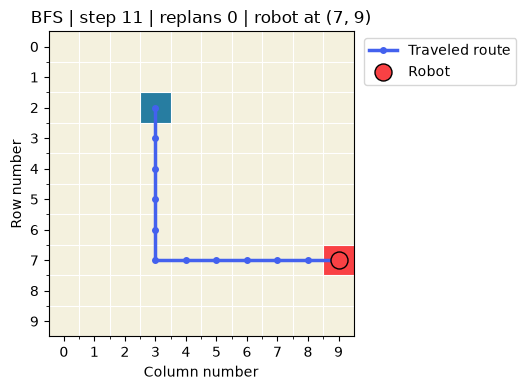

BFS reached the goal in 11 moves with 0 replanning operation(s).


In [12]:
simulate_with_discovery(breadth_first_search, "BFS")


### DFS path simulation
Depth-First Search follows one branch as far as it can before backtracking. It has its own independent search and animation.

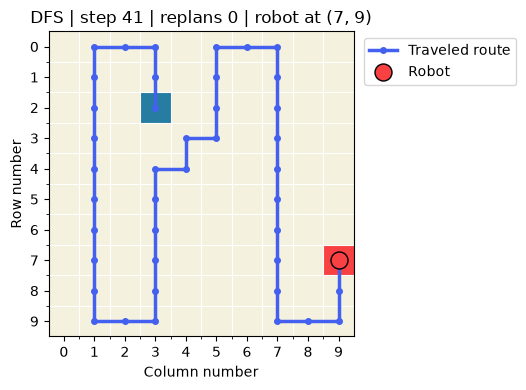

DFS reached the goal in 41 moves with 0 replanning operation(s).


In [13]:
simulate_with_discovery(depth_first_search, "DFS")


## 7. BFS and DFS unknown-blockade discovery and replanning
Each solver plans using the robot’s current known map. When the robot attempts to enter an initially unknown blockade, it reveals the blockade, stays in place, updates its map, and replans to the goal using the same algorithm. The pale blue line is the current plan, the blue line is the traveled route, and the red marker is the robot.\n

## Greedy Best-First Search (GBFS)

Greedy Best-First Search is an informed search algorithm that uses a heuristic to select the most promising state. It expands the node that appears closest to the goal. In our project, it helps the field robot find a path towards the destination while avoiding known obstacles and protected crop regions

#### Working Principle
Initialize a priority queue with the starting position.

Calculate the Manhattan Distance of each neighboring cell.

Select and expand the cell with the lowest heuristic value.

Repeat until the destination is reached or no valid cells remain

8.1 Heuristic Function – Manhattan Distance

A heuristic function estimates the remaining distance from the robot's current position to the destination.

For this project, Manhattan Distance is used because the robot is allowed to move only in four directions: Up, Down, Left and Right. Diagonal movement is not permitted.

Mathematical Formula:

h(n) = |r_current - r_goal| + |c_current - c_goal|

Where:

r_current: Current row of the robot.

c_current: Current column of the robot.

r_goal: Destination row.

c_goal: Destination column.

In [14]:
import heapq
from itertools import count

def manhattan_distance(state, goal):
    """
    Calculate Manhattan Distance between current state and goal.
    """
    return abs(state[0] - goal[0]) + abs(state[1] - goal[1])


def greedy_best_first_search(problem):
    """
    Greedy Best-First Search using Manhattan Distance.
    """

    priority_queue = []
    tie_breaker = count()

    start = problem.start
    goal = problem.goal

    heapq.heappush(
        priority_queue,
        (manhattan_distance(start, goal), next(tie_breaker), start)
    )

    parent = {start: None}
    explored = set()

    while priority_queue:

        _, _, current = heapq.heappop(priority_queue)

        if current in explored:
            continue

        explored.add(current)

        if problem.goal_test(current):
            return reconstruct_path(parent, current)

        for action in problem.actions(current):

            next_state = problem.transition(current, action)

            if next_state not in explored and next_state not in parent:

                parent[next_state] = current

                h = manhattan_distance(next_state, goal)

                heapq.heappush(
                    priority_queue,
                    (h, next(tie_breaker), next_state)
                )

    return None

## GBFS Path Simulation

Greedy Best-First Search selects the next cell based on the lowest heuristic distance to the goal. It uses Manhattan Distance to guide the robot towards the destination. It has its own independent search and animation

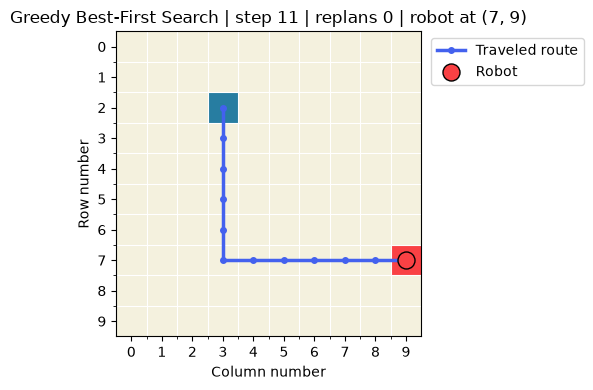

Greedy Best-First Search reached the goal in 11 moves with 0 replanning operation(s).


In [15]:
simulate_with_discovery(greedy_best_first_search,"Greedy Best-First Search")